## Importation data

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
BASE = "https://raw.githubusercontent.com/iabufarha/ArSarcasm-v2/main/ArSarcasm-v2/"
full = pd.read_csv(BASE + "training_data.csv")
test = pd.read_csv(BASE + "testing_data.csv") # scellé jusqu&#39;à la Partie F

full["id"], test["id"] = range(len(full)), range(len(test))
train, val = train_test_split(full, test_size=0.10, random_state=42,stratify=full["sarcasm"])
train = train.reset_index(drop=True).copy()
val = val.reset_index(drop=True).copy()

## Visualisation Data

In [3]:
train.head(30)

,tweet,sarcasm,sentiment,dialect,id
0,"""#لافروف: #موسكو تأمل بإجراء حوار بناء بشأن ال...",False,NEU,msa,2474
1,"""RT @jalalyw: @EHSANFAKEEH تفصيل الخبر لمن يري...",False,NEU,msa,12107
2,تحدثنا عن هذا الكتاب الجميل عن خروج المصريين ع...,False,NEU,msa,2135
3,"""RT @Jokes__99: بوكيمون ولحقتوه عيل المسيح الد...",True,NEG,msa,640
4,"""أوباما يلاحق محمد بن سلمان !!: https://t.co/x...",False,NEU,msa,6766
5,"""تبرعات الهلال الاحمر الكويتي لن تسلم للهلال ا...",False,NEU,msa,5267
6,"""@riyadhalasaad عندما نشاهد مايجري في سوريا من...",False,NEG,msa,1318
7,"""يوسف سونة : دونالد ترامب و هيلاري كلينتون من ...",False,NEU,msa,10003
8,بموت ضحك عطو فرصه لغيركم يحزن,False,NEG,msa,4557
9,في قلبي رجل M❤️ يلغ...,False,POS,msa,49


In [4]:
test.head(30)

,tweet,sarcasm,sentiment,dialect,id
0,اخوي حانق يالغلا وشفيك معصب؟ عادي تراهم بشر يف...,False,NEG,msa,0
1,اف مو متعوده عليهم سته https://t.co/8igFPx1i26,True,NEG,msa,1
2,اللهم اشفِ مرضانا ومرضى المسلمين . . ♥️,False,POS,msa,2
3,ابشركم طلقت السات 😘.,False,POS,gulf,3
4,مؤشر خطير: ٩٠٪ من الشخصيات البرلمانية في الكوي...,True,NEG,msa,4
5,مكتوب للغايب يوم هيعود❤❤اللهم لك الحمد حاسه رو...,False,POS,msa,5
6,اختطاف الأطفال في #الجزائر..العثور على جثة مشو...,False,NEU,msa,6
7,سقف الطموحات المستقبليه بتبقى عاليه ف وقت دراس...,True,NEG,msa,7
8,خرجك ، من قال لك تقول رأيك يحرية ؟ شو ما سمعت ...,False,NEU,msa,8
9,نحن في هذه الحياةإماأن نكونقدوةأوعبرة فقيمتنال...,False,NEU,msa,9


,feature,count,percentage
0,url,4801,38.261077
1,mention,2883,22.975773
2,hashtag,5771,45.991393
3,laugh,201,1.601849
4,repeated_punct,2231,17.779726
5,repeated_letter,652,5.196047
6,latin,6972,55.562639
7,indian_digit,305,2.430666
8,csv_quote_wrap,7617,60.702901
9,tatweel,571,4.550526


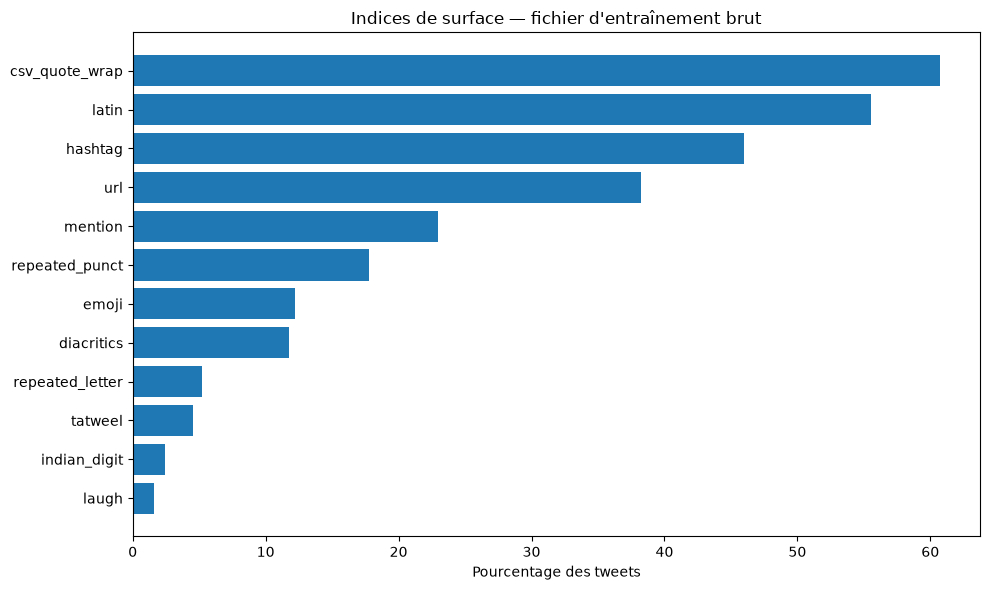

In [5]:
import re
import emoji
from pyarabic.araby import TATWEEL,DIACRITICS
import matplotlib.pyplot as plt



URL_RE = re.compile(r"https?://\S+|www\.\S+", re.IGNORECASE)
MENTION_RE = re.compile(r"(?<!\w)@\w+")
HASHTAG_RE = re.compile(r"(?<!\w)#\w+")
LAUGH_RE = re.compile(r"ه{2,}")
REPEATED_PUNCT_RE = re.compile(r"([!?؟.,،؛…])\1+")
REPEATED_LETTER_RE = re.compile(r"([^\W\d_])\1{2,}")
LATIN_RE = re.compile(r"[A-Za-z]")
INDIAN_DIGIT_RE = re.compile(r"[٠-٩]")
DIACRITIC_CHARS = "".join(ch for ch in DIACRITICS if ch != TATWEEL)
DIACRITIC_RE = re.compile("[" + re.escape(DIACRITIC_CHARS) + "]")
TATWEEL_RE = re.compile(re.escape(TATWEEL))


def has_emoji(text):
    return len(emoji.emoji_list(str(text))) > 0

def has_csv_quote_wrap(text):
    stripped = str(text).strip()
    return len(stripped) >= 2 and stripped[0] == '"' and stripped[-1] == '"'

CUES = [
    ("url", lambda text: bool(URL_RE.search(text))),
    ("mention", lambda text: bool(MENTION_RE.search(text))),
    ("hashtag", lambda text: bool(HASHTAG_RE.search(text))),
    ("laugh", lambda text: bool(LAUGH_RE.search(text))),
    ("repeated_punct", lambda text: bool(REPEATED_PUNCT_RE.search(text))),
    ("repeated_letter", lambda text: bool(REPEATED_LETTER_RE.search(text))),
    ("latin", lambda text: bool(LATIN_RE.search(text))),
    ("indian_digit", lambda text: bool(INDIAN_DIGIT_RE.search(text))),
    ("csv_quote_wrap", has_csv_quote_wrap),
    ("tatweel", lambda text: bool(TATWEEL_RE.search(text))),
    ("diacritics", lambda text: bool(DIACRITIC_RE.search(text))),
    ("emoji", has_emoji),
]

tweets = full["tweet"].astype(str)

rows = []
for name, function in CUES:
    present = tweets.map(function).astype(bool)
    rows.append(
        {
            "feature": name,
            "count": present.sum(),
            "percentage": 100 * present.mean(),
        }
    )

audit = pd.DataFrame(rows)
display(audit)

fig, ax = plt.subplots(figsize=(10, 6))
order = audit.sort_values("percentage", ascending=True)
ax.barh(order["feature"], order["percentage"])
ax.set_xlabel("Pourcentage des tweets")
ax.set_title("Indices de surface — fichier d'entraînement brut")
fig.tight_layout()
display(fig)
plt.close(fig)



In [6]:
print(train["dialect"].unique())
print(train["sentiment"].unique())

<StringArray>
['msa', 'egypt', 'levant', 'gulf', 'magreb']
Length: 5, dtype: str
<StringArray>
['NEU', 'NEG', 'POS']
Length: 3, dtype: str


## Exploration de data

In [7]:
import matplotlib.pyplot as plt 
import seaborn as sns

dialect_order = ['msa', 'egypt', 'levant', 'gulf', 'magreb']
sentiment_order = ['NEG', 'NEU', 'POS']



### Pourcentage de sarcasme par dialecte

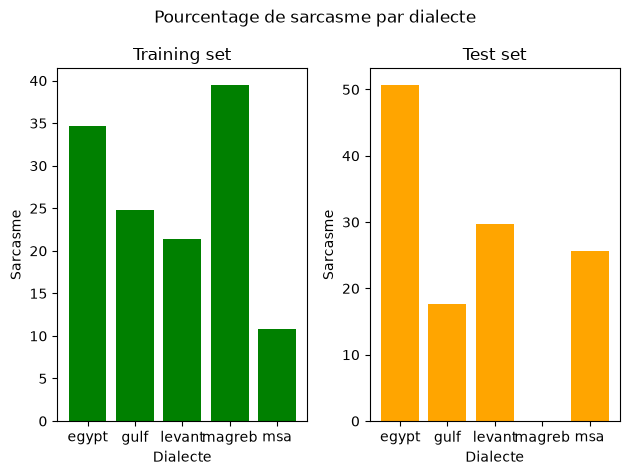

In [8]:
df_sar_dialect_train = train.groupby('dialect')['sarcasm'].value_counts(normalize=True).unstack() * 100
df_sar_dialect_test = test.groupby('dialect')['sarcasm'].value_counts(normalize=True).unstack() * 100

fig, (ax1, ax2) = plt.subplots(1, 2)

fig.suptitle('Pourcentage de sarcasme par dialecte')

ax1.bar(df_sar_dialect_train.index, df_sar_dialect_train[True], color='green')

ax2.bar(df_sar_dialect_test.index, df_sar_dialect_test[True], color='orange')

ax1.set_title("Training set")
ax1.set_xlabel("Dialecte")
ax1.set_ylabel("Sarcasme")
ax2.set_title("Test set")
ax2.set_xlabel("Dialecte")
ax2.set_ylabel("Sarcasme")

fig.tight_layout()
display(fig)
plt.close(fig)



### Pourcentage de sarcasme par sentiment.

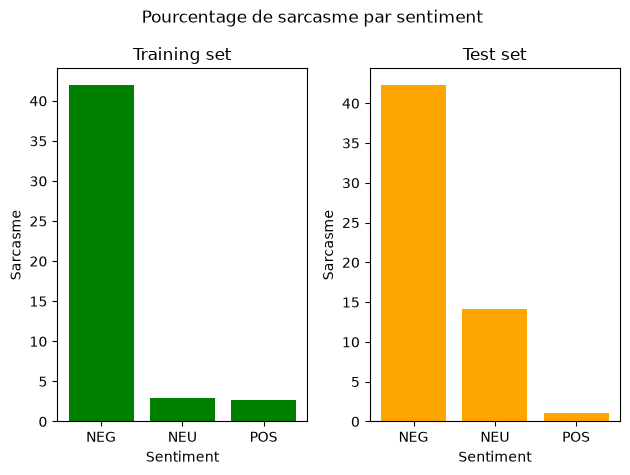

<Figure size 1000x600 with 0 Axes>

In [9]:
df_sar_sentiment_train = train.groupby('sentiment')['sarcasm'].value_counts(normalize=True).unstack() * 100
df_sar_sentiment_test = test.groupby('sentiment')['sarcasm'].value_counts(normalize=True).unstack() * 100
plt.figure(figsize=(10, 6))
fig, (ax1, ax2) = plt.subplots(1, 2)

fig.suptitle('Pourcentage de sarcasme par sentiment ')

ax1.bar(df_sar_sentiment_train.index, df_sar_sentiment_train[True], color='green')

ax2.bar(df_sar_sentiment_test.index, df_sar_sentiment_test[True], color='orange')

ax1.set_title("Training set")
ax1.set_xlabel("Sentiment")
ax1.set_ylabel("Sarcasme")
ax2.set_title("Test set")
ax2.set_xlabel("Sentiment")
ax2.set_ylabel("Sarcasme")

fig.tight_layout()
display(fig)
plt.close(fig)


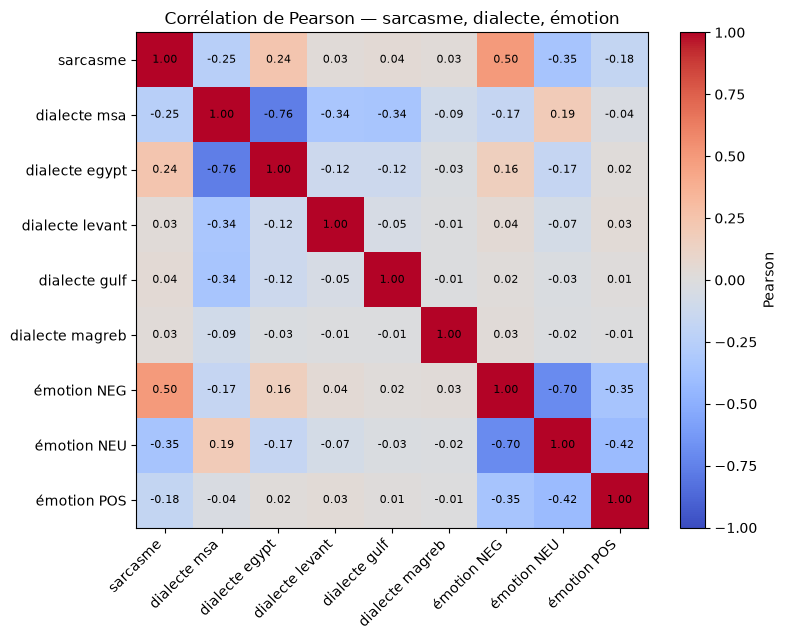

In [10]:
encoded = pd.get_dummies(full[["dialect", "sentiment"]].astype(str))
encoded.insert(0, "sarcasm", full["sarcasm"].astype(int))
order = (
    ["sarcasm"]
    + [f"dialect_{name}" for name in dialect_order]
    + [f"sentiment_{name}" for name in sentiment_order]
)
corr = encoded.corr(method="pearson").reindex(index=order, columns=order)
labels = ["sarcasme"] + [f"dialecte {name}" for name in dialect_order] + [f"émotion {name}" for name in sentiment_order]
fig, ax = plt.subplots(figsize=(8, 6.5))
image = ax.imshow(corr.to_numpy(), vmin=-1, vmax=1, cmap="coolwarm", aspect="auto")
ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
ax.set_yticks(range(len(labels)), labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        value = corr.iloc[i, j]
        ax.text(j, i, "" if pd.isna(value) else f"{value:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Corrélation de Pearson — sarcasme, dialecte, émotion")
fig.colorbar(image, ax=ax, label="Pearson")
fig.tight_layout()
display(fig)
plt.close(fig)

,feature,count,pct_tweets (%),sarcasm_when_present (%),sarcasm_when_absent (%),pearson_with_sarcasm
3,laugh,201,1.60,50.75,16.73,0.1130
5,repeated_letter,652,5.20,30.83,16.53,0.0839
4,repeated_punct,2231,17.78,20.71,16.54,0.0422
1,mention,2883,22.98,17.20,17.30,-0.0011
9,tatweel,571,4.55,16.99,17.29,-0.0017
11,emoji,1528,12.18,16.75,17.35,-0.0052
7,indian_digit,305,2.43,11.48,17.42,-0.0242
10,diacritics,1475,11.75,12.81,17.87,-0.0431
2,hashtag,5771,45.99,15.01,19.21,-0.0554
8,csv_quote_wrap,7617,60.70,12.52,24.62,-0.1563


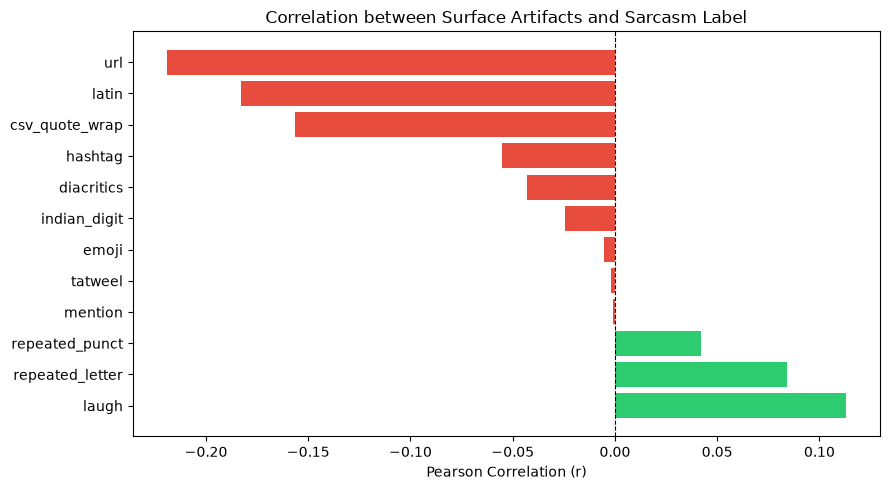

In [ ]:
tweets = full["tweet"].astype(str)
labels = full["sarcasm"].astype(float)

rows = []
for name, func in CUES:
    present = tweets.map(func).astype(float)
    corr = present.corr(labels)
    
    rows.append({
        "feature": name,
        "count": int(present.sum()),
        "pct_tweets (%)": round(100 * present.mean(), 2),
        "sarcasm_when_present (%)": round(100 * labels[present == 1].mean(), 2),
        "sarcasm_when_absent (%)": round(100 * labels[present == 0].mean(), 2),
        "pearson_with_sarcasm": round(corr, 4),
    })

corr_df = pd.DataFrame(rows).sort_values("pearson_with_sarcasm", ascending=False)
display(corr_df)

# Plot the correlations
plt.figure(figsize=(9, 5))
colors = ["#e74c3c" if x < 0 else "#2ecc71" for x in corr_df["pearson_with_sarcasm"]]
plt.barh(corr_df["feature"], corr_df["pearson_with_sarcasm"], color=colors)
plt.axvline(0, color="black", linestyle="--", linewidth=0.8)
plt.xlabel("Pearson Correlation (r)")
plt.title("Correlation between Surface Artifacts and Sarcasm Label")
plt.tight_layout()
plt.show()


In [12]:
from sklearn.metrics import accuracy_score, f1_score

# Baseline trivial : prédire "jamais sarcastique" pour tous les tweets
y_true = val["sarcasm"].astype(int)
y_pred = [0] * len(val)

acc = accuracy_score(y_true, y_pred)
f1_pos = f1_score(y_true, y_pred, pos_label=1, zero_division=0)

print(f"Accuracy (baseline 'jamais sarcastique') : {acc:.4f}")
print(f"F1-score (classe sarcastique = 1) : {f1_pos:.4f}")
print(f"Part de sarcasme dans val : {y_true.mean():.4f}")


Accuracy (baseline 'jamais sarcastique') : 0.8271
F1-score (classe sarcastique = 1) : 0.0000
Part de sarcasme dans val : 0.1729


### Conclusion : 
l'accuracy est élevée si la majorité des exemples sont non sarcastiques,
mais cela ne signifie pas que le modèle est bon pour détecter le sarcasme.

In [13]:
#export the train, val, and test datasets to CSV files
ROOT = "./data/"
train.to_csv(ROOT + "train.csv", index=False)
val.to_csv(ROOT + "val.csv", index=False)
test.to_csv(ROOT + "test.csv", index=False)
